In [5]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error

from xgboost import XGBRegressor

In [6]:
data_path = Path("data/yellow_tripdata_2026-05.parquet")

df = pd.read_parquet(data_path)

df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1.0,7.51,1.0,N,138,37,2,35.9,6.00,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1.0,6.14,1.0,N,138,237,1,27.5,6.00,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1.0,2.40,1.0,N,249,232,1,19.1,4.25,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0.0,1.20,1.0,N,232,114,1,9.3,4.25,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2.0,0.86,1.0,N,140,237,1,7.2,0.00,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00


In [7]:
df.shape

(4090836, 20)

In [8]:
df.shape

(4090836, 20)

In [9]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

In [10]:
df[["tpep_pickup_datetime", "tpep_dropoff_datetime", "duration"]].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,duration
0,2026-05-01 00:04:59,2026-05-01 00:32:48,27.816667
1,2026-05-01 00:37:05,2026-05-01 00:59:47,22.700000
2,2026-05-01 00:34:05,2026-05-01 00:54:02,19.950000
3,2026-05-01 00:55:07,2026-05-01 01:02:43,7.600000
4,2026-05-01 00:44:13,2026-05-01 00:44:13,0.000000


In [11]:
df[["tpep_pickup_datetime", "tpep_dropoff_datetime", "duration"]].head(10)

,tpep_pickup_datetime,tpep_dropoff_datetime,duration
0,2026-05-01 00:04:59,2026-05-01 00:32:48,27.816667
1,2026-05-01 00:37:05,2026-05-01 00:59:47,22.700000
2,2026-05-01 00:34:05,2026-05-01 00:54:02,19.950000
3,2026-05-01 00:55:07,2026-05-01 01:02:43,7.600000
4,2026-05-01 00:44:13,2026-05-01 00:44:13,0.000000
5,2026-05-01 00:24:35,2026-05-01 00:49:55,25.333333
6,2026-05-01 00:06:08,2026-05-01 00:12:47,6.650000
7,2026-05-01 00:49:20,2026-05-01 01:06:36,17.266667
8,2026-05-01 00:29:38,2026-05-01 00:32:49,3.183333
9,2026-05-01 00:39:07,2026-05-01 00:48:32,9.416667


In [12]:
df = df[(df["duration"] >= 1) & (df["duration"] <= 60)].copy()

df.shape

(3883752, 21)

In [13]:
df["PULocationID"] = df["PULocationID"].astype(str)
df["DOLocationID"] = df["DOLocationID"].astype(str)

df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

In [14]:
df[["PULocationID", "DOLocationID", "PU_DO"]].head()

,PULocationID,DOLocationID,PU_DO
0,138,37,138_37
1,138,237,138_237
2,249,232,249_232
3,232,114,232_114
5,255,236,255_236


In [15]:
categorical = ["PULocationID", "DOLocationID", "PU_DO"]
numerical = ["trip_distance"]

df[categorical + numerical].head()

,PULocationID,DOLocationID,PU_DO,trip_distance
0,138,37,138_37,7.51
1,138,237,138_237,6.14
2,249,232,249_232,2.40
3,232,114,232_114,1.20
5,255,236,255_236,5.89


In [16]:
df = df.sample(n=min(200_000, len(df)), random_state=42)

df.shape

(200000, 22)

In [17]:
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

df[["tpep_pickup_datetime", "duration"]].head()

,tpep_pickup_datetime,duration
0,2026-05-01 00:00:11,14.416667
1,2026-05-01 00:00:30,10.733333
2,2026-05-01 00:00:35,24.433333
3,2026-05-01 00:00:54,21.183333
4,2026-05-01 00:00:57,33.416667


In [18]:
train_size = int(len(df) * 0.8)

df_train = df.iloc[:train_size].copy()
df_val = df.iloc[train_size:].copy()

print("Entraînement :", df_train.shape)
print("Validation :", df_val.shape)

Entraînement : (160000, 22)
Validation : (40000, 22)


In [19]:
train_dicts = df_train[categorical + numerical].to_dict(orient="records")
val_dicts = df_val[categorical + numerical].to_dict(orient="records")

dv = DictVectorizer()

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print("X_train :", X_train.shape)
print("X_val :", X_val.shape)

X_train : (160000, 13134)
X_val : (40000, 13134)


In [20]:
y_train = df_train["duration"].values
y_val = df_val["duration"].values

print("y_train :", y_train.shape)
print("y_val :", y_val.shape)

y_train : (160000,)
y_val : (40000,)


In [21]:
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_val)

rmse = root_mean_squared_error(y_val, y_pred)

print("RMSE Linear Regression :", rmse)

RMSE Linear Regression : 6.660238939545925


In [22]:
X_train = X_train.astype("float64").tocsr()
X_val = X_val.astype("float64").tocsr()

X_train.indices = X_train.indices.astype("int32")
X_train.indptr = X_train.indptr.astype("int32")

X_val.indices = X_val.indices.astype("int32")
X_val.indptr = X_val.indptr.astype("int32")

In [23]:
lasso = Lasso(alpha=0.01)
lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_val)

rmse_lasso = root_mean_squared_error(y_val, y_pred_lasso)

print("RMSE Lasso :", rmse_lasso)

RMSE Lasso : 9.423958031547887


In [24]:
xgb = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=42
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_val)

rmse_xgb = root_mean_squared_error(y_val, y_pred_xgb)

print("RMSE XGBoost :", rmse_xgb)

RMSE XGBoost : 6.261848890952312


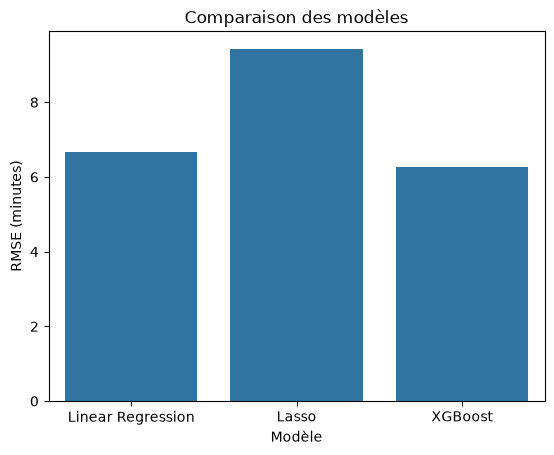

In [25]:
results = pd.DataFrame({
    "Modèle": ["Linear Regression", "Lasso", "XGBoost"],
    "RMSE": [rmse, rmse_lasso, rmse_xgb]
})

sns.barplot(data=results, x="Modèle", y="RMSE")
plt.title("Comparaison des modèles")
plt.ylabel("RMSE (minutes)")
plt.show()

In [26]:
lasso_2 = Lasso(alpha=0.001)
lasso_2.fit(X_train, y_train)

y_pred_lasso_2 = lasso_2.predict(X_val)

rmse_lasso_2 = root_mean_squared_error(y_val, y_pred_lasso_2)

print("RMSE Lasso alpha=0.001 :", rmse_lasso_2)

RMSE Lasso alpha=0.001 : 7.6454583137268655


In [27]:
xgb_2 = XGBRegressor(
    n_estimators=100,
    max_depth=8,
    learning_rate=0.1,
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=42
)

xgb_2.fit(X_train, y_train)

y_pred_xgb_2 = xgb_2.predict(X_val)

rmse_xgb_2 = root_mean_squared_error(y_val, y_pred_xgb_2)

print("RMSE XGBoost max_depth=8 :", rmse_xgb_2)

RMSE XGBoost max_depth=8 : 6.200741245983183


In [28]:
results_tuning = pd.DataFrame({
    "Modèle": [
        "Linear Regression",
        "Lasso alpha=0.01",
        "Lasso alpha=0.001",
        "XGBoost depth=6",
        "XGBoost depth=8"
    ],
    "RMSE": [
        rmse,
        rmse_lasso,
        rmse_lasso_2,
        rmse_xgb,
        rmse_xgb_2
    ]
})

results_tuning.sort_values("RMSE")

,Modèle,RMSE
4,XGBoost depth=8,6.200741
3,XGBoost depth=6,6.261849
0,Linear Regression,6.660239
2,Lasso alpha=0.001,7.645458
1,Lasso alpha=0.01,9.423958


In [29]:
selected_model = xgb_2

print("Modèle sélectionné : XGBoost")
print("RMSE :", rmse_xgb_2)

Modèle sélectionné : XGBoost
RMSE : 6.200741245983183


In [30]:

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

with open(model_dir / "duration_model.bin", "wb") as f:
    pickle.dump((dv, selected_model), f)

print("Modèle sauvegardé avec succès !")

Modèle sauvegardé avec succès !


In [31]:
with open("models/duration_model.bin", "rb") as f:
    dv_loaded, model_loaded = pickle.load(f)

print("Modèle rechargé avec succès !")

Modèle rechargé avec succès !


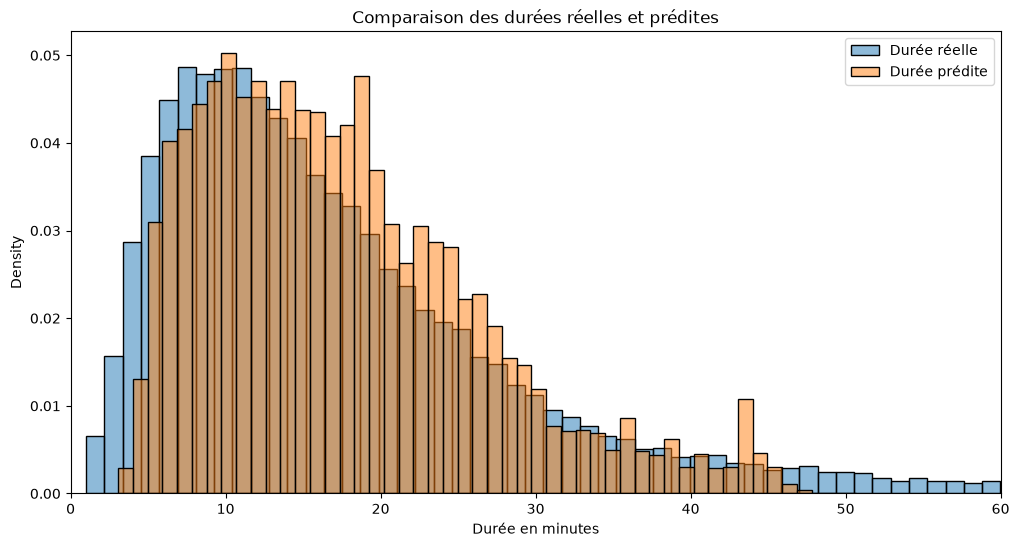

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(
    y_val,
    label="Durée réelle",
    stat="density",
    bins=50,
    alpha=0.5
)

sns.histplot(
    y_pred_xgb_2,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5
)

plt.xlabel("Durée en minutes")
plt.ylabel("Density")
plt.title("Comparaison des durées réelles et prédites")
plt.legend()
plt.xlim(0, 60)
plt.show()